# Iris Classification with k-Nearest Neighbors
Author: Manuel Eugenio Morocho Cayamcela, PhD

## Introduction
Use supervised learning to classify 150 Iris flowers into three species from four measurements: sepal length, sepal width, petal length, and petal width (in centimeters). This lesson covers loading data, exploration, preprocessing, training a k-nearest neighbors (k-NN) classifier, saving the model, and evaluating predictions.

![Iris species and flower measurements](https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Unit%205.%20Machine%20Learning%20as%20an%20AI%20Component/5.3%20Unsupervised%20learning/5.3.1%20k-Means/iris.png)

## Setup
If needed, install the packages once with `%pip install pandas matplotlib seaborn scikit-learn joblib`. Restart the kernel after installation if requested.

In [21]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Load the Iris dataset
Read the Iris CSV directly from GitHub using pandas. An internet connection is required.

In [22]:
github_url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/iris.csv"
iris = pd.read_csv(github_url)

## Explore and prepare the data
Run each cell separately and inspect its output before continuing.

Preview the first five records.

In [23]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Inspect column types and non-null counts to identify missing values.

In [24]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


Summarize the numeric columns.

In [25]:
iris.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Count the examples of each species.

In [26]:
iris["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Remove `Id`: it identifies records rather than measuring flowers.

In [27]:
iris = iris.drop(columns="Id")

## Visualize the measurements
Compare sepal and petal measurements by species. Setosa is particularly distinct in petal measurements; versicolor and virginica overlap more. These plots help assess whether the measurements can separate the classes.

### Sepal measurements

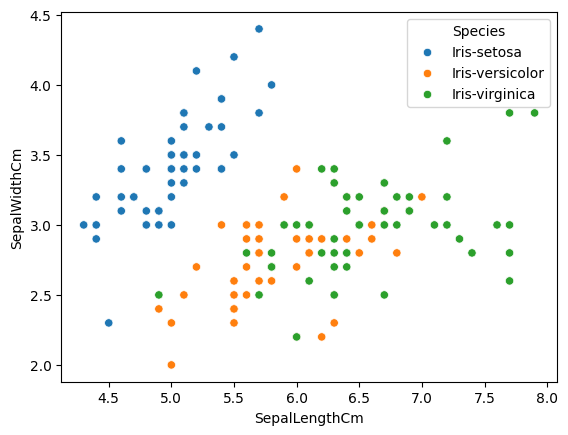

In [28]:
sns.scatterplot(data=iris, x="SepalLengthCm", y="SepalWidthCm", hue="Species")
plt.show()

### Petal measurements

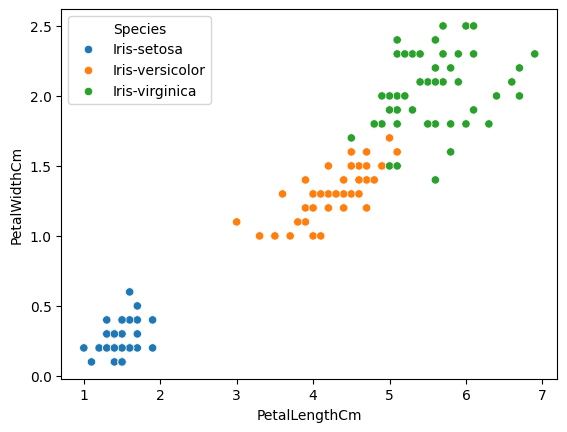

In [29]:
sns.scatterplot(data=iris, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

The pair plot compares every pair of measurements. Histograms on the diagonal show each feature's distribution.

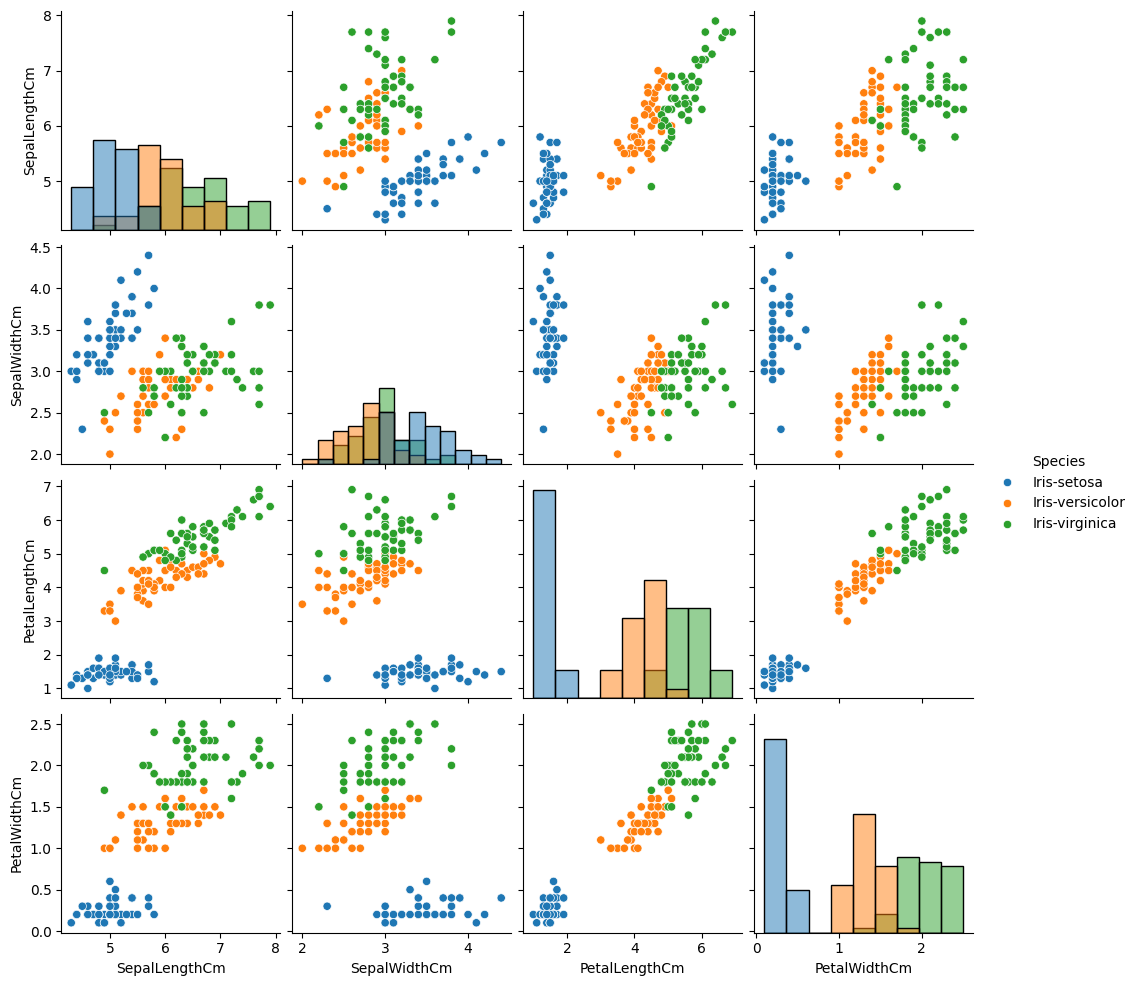

In [30]:
sns.pairplot(iris, hue="Species", diag_kind="hist")
plt.show()

## Prepare training and test sets
Separate the four predictors (`X`) from the species label (`y`). Reserve 20% of the data for testing. Stratification preserves class proportions, and a fixed random seed makes the split reproducible. Keep the test set out of model fitting.

In [47]:
# Isolate features
X = iris.drop(columns="Species")

# Isolate target variable
y = iris["Species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Train the k-NN classifier
With `n_neighbors=5`, the classifier predicts a flower's species from the majority class among its five nearest training examples. Fit the model on the training set only.

In [43]:
from sklearn.neighbors import KNeighborsClassifier

classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train, y_train)

KNeighborsClassifier()

## Evaluate on unseen data
Predict the species of the held-out examples.

In [44]:
predictions = classifier.predict(X_test)
predictions

array(['Iris-versicolor', 'Iris-setosa', 'Iris-virginica',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-setosa',
       'Iris-versicolor', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-virginica', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-setosa', 'Iris-versicolor', 'Iris-virginica',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-virginica',
       'Iris-setosa', 'Iris-virginica', 'Iris-setosa', 'Iris-virginica',
       'Iris-virginica', 'Iris-virginica', 'Iris-virginica',
       'Iris-virginica', 'Iris-setosa', 'Iris-setosa'], dtype=object)

### Accuracy
Accuracy is the fraction of correctly classified test examples.

In [45]:
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")

Test accuracy: 1.000


### Classification report
The report summarizes each species:

- **Precision:** TP / (TP + FP), the fraction of predictions for that species that are correct.
- **Recall:** TP / (TP + FN), the fraction of actual flowers of that species correctly identified.
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of true examples of that species in the test set.

Interpret the results generated below; scores can change with the split and model settings.

In [46]:
print(classification_report(y_test, predictions, zero_division=0))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



### Confusion matrix
Rows show actual classes and columns show predicted classes. Diagonal entries are correct predictions.

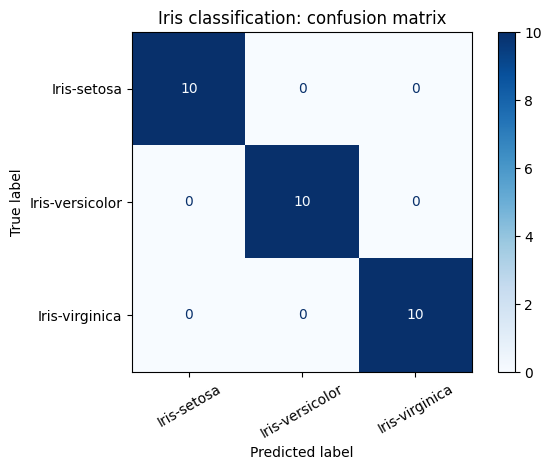

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=classifier.classes_, cmap="Blues"
)
plt.title("Iris classification: confusion matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Save and reload the trained model
Save the fitted classifier for reuse without retraining. Only load model files you trust. The file is written to the current working directory.

In [48]:
import joblib

model_path = Path("knn_model.pkl")
joblib.dump(classifier, model_path)

['knn_model.pkl']

In [49]:
loaded_classifier = joblib.load(model_path)
loaded_classifier.predict(X_test.head())

array(['Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa'], dtype=object)

## Activity: Data Preprocessing and Customer Classification with k-NN
### Objective
Explore a classification dataset, train k-NN, and select a suitable value of `k`. Work individually or in a group, share the work fairly, and justify your decisions.

### Where to find datasets
For this short activity, choose a small tabular dataset with a clearly documented categorical target. Prefer CSV files and numeric predictors so that data preparation remains manageable.

- [UCI Machine Learning Repository](https://archive.ics.uci.edu/): a useful starting point for classification datasets.
- [Kaggle Datasets](https://www.kaggle.com/datasets): browse datasets and select one with a documented target and downloadable tabular files. Check access requirements before choosing it.
- [Awesome Public Datasets on GitHub](https://github.com/awesomedata/awesome-public-datasets): a topic-based directory linking to datasets; check the original source for files and documentation.
- [Ecuador Open Data Portal — CSV datasets](https://www.datosabiertos.gob.ec/dataset/?res_format=CSV): explore Ecuadorian public data available in CSV format.
- [INEC Open Data Bank](https://aplicaciones3.ecuadorencifras.gob.ec/BIINEC-war/index.xhtml): find Ecuadorian statistical information and consult the accompanying documentation.
- [U.S. Government Open Data](https://data.gov/): search public datasets by topic or organization.

Government portals are useful for local or applied topics, but their tables may require more cleaning and may not have a ready-made classification target. Verify the target column and download format before committing to a dataset.

### Instructions
1. **Find and explore a dataset (10 minutes).** Load a classification dataset, inspect its structure, and clean or transform it as needed.

In [ ]:
# Import the dataset


2. **Classify with k-NN (20 minutes).** Split the data into training and test sets, train the classifier, and report accuracy. Select `k` using only training data (for example, cross-validation), then evaluate the chosen model on the test set. Predict a new example outside both sets.

In [ ]:
# Select the best k value for the k-NN classifier


# Fit a k-NN classifier to the training data


3. **Present the dataset and process (30 minutes).** Explain decisions and results, and discuss possible improvements.


Write a brief explanation of the dataset, preprocessing steps, and model evaluation...


### Assessment
- Dataset source: 10%.
- Training/test split: 20%.
- Justification of the chosen `k`: 40%.
- Classification metrics: 30%.

### Deliverable
Submit the Jupyter notebook results as a PDF.